In [1]:
import pandas as pd
df = pd.read_csv("data/train.csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## ISLR Ch. 1 notes

1. **Statistical learning:** a set of tools that use data to understand the relationship between inputs and an output, so we can predict or explain the output.

2. **Supervised vs. unsupervised:** supervised learning has an output we try to predict from inputs (e.g. Wage data). Unsupervised learning has only inputs, and we look for structure such as groups (e.g. gene clustering).

3. **Regression vs. classification:** regression predicts a numerical output, like a house price. Classification predicts a category, like market up or down.

4. **Prediction vs. inference:** prediction is guessing the output accurately for new inputs, without needing to explain why. Inference is understanding how each input affects the output ("what happens to the output if I change this input?").

5. **My Ames project:** supervised regression. The output is SalePrice (a number), and I care about both prediction (accuracy on new houses) and inference (which features drive price). Coefficients show association, not causation.

In [2]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [3]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [4]:
df['Neighborhood'].value_counts()

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

In [5]:
#which columns have missing values, and how many
df.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [6]:
# are the "missing" MasVnrType rows really houses with zero veneer area?
df.loc[df['MasVnrType'].isna(), 'MasVnrArea'].value_counts().head()

MasVnrArea
0.0      859
1.0        2
288.0      1
344.0      1
312.0      1
Name: count, dtype: int64

In [7]:
# the skew in prices
print(df['SalePrice'].mean(), df['SalePrice'].median(), df['SalePrice'].skew())

180921.19589041095 163000.0 1.8828757597682129


In [8]:
df[df['BsmtExposure'].isna() & df['BsmtQual'].notna()][['BsmtQual','BsmtExposure','BsmtFinType2']]

,BsmtQual,BsmtExposure,BsmtFinType2
948,Gd,NaN,Unf


In [9]:
import numpy as np
print(np.log(df['SalePrice']).skew())


0.12133506220520406


In [10]:
df_clean = df.copy()

# 1. "NA" means no such feature
none_cols = ['Alley','PoolQC','Fence','MiscFeature','FireplaceQu',
             'GarageType','GarageFinish','GarageQual','GarageCond',
             'BsmtQual','BsmtCond','BsmtFinType1']
df_clean[none_cols] = df_clean[none_cols].fillna('None')

# 2. Veneer: area 0 means no veneer
df_clean.loc[df_clean['MasVnrArea'] == 0, 'MasVnrType'] = 'None'

In [11]:
df[df['BsmtFinType2'].isna() & df['BsmtQual'].notna()][['BsmtQual','BsmtFinType1','BsmtFinType2']]

,BsmtQual,BsmtFinType1,BsmtFinType2
332,Gd,GLQ,NaN


In [12]:
df.loc[332, ['BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2']]

BsmtFinType1     GLQ
BsmtFinSF1      1124
BsmtFinType2     NaN
BsmtFinSF2       479
Name: 332, dtype: object

In [13]:
df.loc[df['BsmtFinSF2'] > 0, 'BsmtFinType2'].value_counts()

BsmtFinType2
Rec    54
LwQ    46
BLQ    33
ALQ    19
GLQ    14
Name: count, dtype: int64

In [14]:
has_bsmt = df['BsmtQual'].notna()

# 37 houses with no basement: feature absent
for c in ['BsmtExposure', 'BsmtFinType2']:
    df_clean.loc[~has_bsmt, c] = 'None'

# Row 948: basement exists, exposure unrecorded -> most common value (assumption)
df_clean.loc[948, 'BsmtExposure'] = df.loc[has_bsmt, 'BsmtExposure'].mode()[0]

# Row 332: second finished area exists, type unrecorded
fin2_fill = df.loc[df['BsmtFinSF2'] > 0, 'BsmtFinType2'].mode()[0]
df_clean.loc[332, 'BsmtFinType2'] = fin2_fill

In [15]:
fin2_fill = df.loc[df['BsmtFinSF2'] > 0, 'BsmtFinType2'].mode()[0]
print(fin2_fill)  # should print Rec
df_clean.loc[332, 'BsmtFinType2'] = fin2_fill

Rec


In [16]:
df_clean[['BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2']].isna().sum()

BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64

In [17]:
df_clean.isna().sum().loc[lambda s: s > 0]


LotFrontage    259
MasVnrType      13
MasVnrArea       8
Electrical       1
GarageYrBlt     81
dtype: int64

In [18]:
df_clean['HasGarage'] = df['GarageType'].notna().astype(int)
df_clean['GarageBuiltLater'] = (df['GarageYrBlt'] - df['YearBuilt']).fillna(0)
df_clean = df_clean.drop(columns='GarageYrBlt')

In [19]:
df_clean['Electrical'] = df_clean['Electrical'].fillna(df['Electrical'].mode()[0])

In [20]:
df_clean['MasVnrArea'] = df_clean['MasVnrArea'].fillna(0)
df_clean.loc[df_clean['MasVnrArea'] == 0, 'MasVnrType'] = 'None'
df_clean['MasVnrType'] = df_clean['MasVnrType'].fillna(df['MasVnrType'].mode()[0])

In [21]:
df_clean.isna().sum().loc[lambda s: s > 0]

LotFrontage    259
dtype: int64

## Cleaning log
- Blanks in Alley, PoolQC, Fence, MiscFeature, FireplaceQu, garage and basement columns mean the house has no such feature, so I filled them with "None".
- Rows 948 and 332 have a basement but one value is unrecorded, so I filled them with the most common value (an assumption).
- Garage year: replaced with HasGarage and GarageBuiltLater (garage year minus house year).
- Electrical: every house has wiring, so I filled the 1 blank with the most common type.
- Masonry veneer: area blank set to 0, type set to "None" where area is 0, leftovers filled with the most common type.
- LotFrontage (259 blank): will fill with the neighbourhood median, calculated from the training set only, after the split.

## My observations
The average house price ($180,921) is higher than the middle price ($163,000), because a few very expensive houses pull the average up.
81 houses have no garage and 37 have no basement.
The neighbourhood Blueste has only 2 houses, so I can’t trust any price estimate for it.
One house has a lot of 215,245 square feet, much bigger than the typical 9,478, so it is an outlier I need to check.
After taking the log of price, the skew went from 1.88 to 0.12, so log price is almost symmetric and better for modelling.


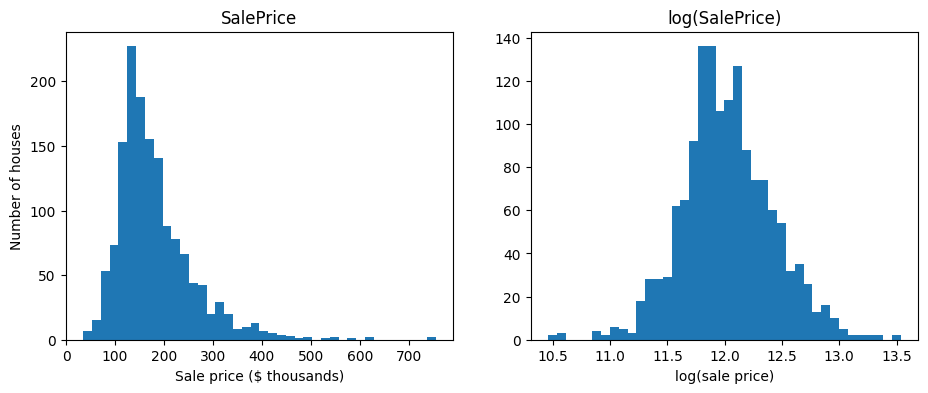

In [22]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df_clean['SalePrice'] / 1000, bins=40)
axes[0].set_title('SalePrice')
axes[0].set_xlabel('Sale price ($ thousands)')
axes[0].set_ylabel('Number of houses')

axes[1].hist(np.log(df_clean['SalePrice']), bins=40)
axes[1].set_title('log(SalePrice)')
axes[1].set_xlabel('log(sale price)')

plt.tight_layout
fig.savefig('price_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

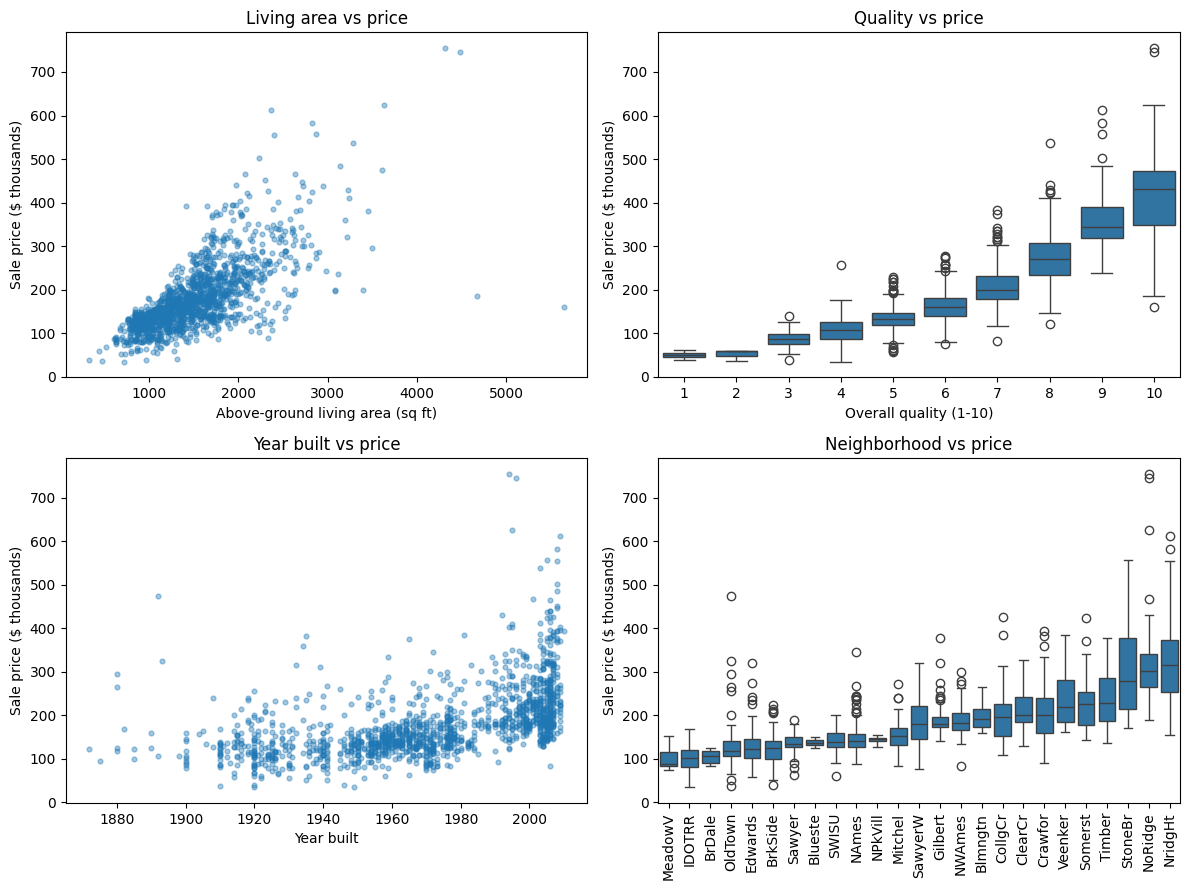

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
price_k = df_clean['SalePrice'] / 1000

# 1. Size vs price
axes[0, 0].scatter(df_clean['GrLivArea'], price_k, alpha=0.4, s=12)
axes[0, 0].set_xlabel('Above-ground living area (sq ft)')
axes[0, 0].set_ylabel('Sale price ($ thousands)')
axes[0, 0].set_title('Living area vs price')

# 2. Quality vs price
sns.boxplot(x=df_clean['OverallQual'], y=price_k, ax=axes[0, 1])
axes[0, 1].set_xlabel('Overall quality (1-10)')
axes[0, 1].set_ylabel('Sale price ($ thousands)')
axes[0, 1].set_title('Quality vs price')

# 3. Age vs price
axes[1, 0].scatter(df_clean['YearBuilt'], price_k, alpha=0.4, s=12)
axes[1, 0].set_xlabel('Year built')
axes[1, 0].set_ylabel('Sale price ($ thousands)')
axes[1, 0].set_title('Year built vs price')

# 4. Neighborhood vs price (sorted by median)
order = df_clean.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(x=df_clean['Neighborhood'], y=price_k, order=order, ax=axes[1, 1])
axes[1, 1].tick_params(axis='x', rotation=90)
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Sale price ($ thousands)')
axes[1, 1].set_title('Neighborhood vs price')

plt.tight_layout()
fig.savefig('bivariate.png', dpi=200, bbox_inches='tight')
plt.show()

In [24]:
df_clean.loc[df_clean['GrLivArea'] > 4000, ['GrLivArea', 'SalePrice', 'SaleCondition', 'Neighborhood']]

,GrLivArea,SalePrice,SaleCondition,Neighborhood
523,4676,184750,Partial,Edwards
691,4316,755000,Normal,NoRidge
1182,4476,745000,Abnorml,NoRidge
1298,5642,160000,Partial,Edwards


In [25]:
df_clean = df_clean.drop(index=[523, 1298])
print(df_clean.shape)

(1458, 82)


Removed 2 houses above 4,000 sq ft with SaleCondition = Partial and low prices (rows 523 and 1298); they are unfinished-sale cases that don’t reflect the typical relationship between size and price